# RunCast · pipeline trenowania modelu

Notebook jest pipelinem, który:

1. **wczytuje dane** z Digital Ocean Spaces (gdy w `.env` nie ma kluczy — z folderu `data/`),
2. **czyści** je,
3. **wybiera cechy** (feature selection) na podstawie metryk,
4. **trenuje i ocenia** model,
5. **zapisuje nową wersję** modelu lokalnie (`model/`) i do Digital Ocean Spaces.

Aplikacja (`app.py`) używa pliku `model/tempomat.joblib`, który powstaje na końcu tego notebooka.

**Potrzebne zmienne w `.env`** (dla Spaces):
`AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`, `AWS_ENDPOINT_URL_S3` (np. `https://fra1.digitaloceanspaces.com`), `BUCKET_NAME`.

## 0. Konfiguracja

In [1]:
import json
import os
from datetime import datetime
from pathlib import Path

import boto3
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

load_dotenv()

BUCKET_NAME = os.getenv("BUCKET_NAME")
DANE_PREFIX = "runcast/data/"     # tu leżą CSV w Spaces
MODEL_PREFIX = "runcast/models/"  # tu trafiają wersje modelu w Spaces
PLIKI = {2023: "halfmarathon_wroclaw_2023__final.csv", 2024: "halfmarathon_wroclaw_2024__final.csv"}
DANE_DIR, MODEL_DIR = Path("data"), Path("model")

SPACES = all(os.getenv(k) for k in ("AWS_ACCESS_KEY_ID", "AWS_SECRET_ACCESS_KEY", "AWS_ENDPOINT_URL_S3", "BUCKET_NAME"))
s3 = boto3.client("s3", endpoint_url=os.getenv("AWS_ENDPOINT_URL_S3")) if SPACES else None
print("Digital Ocean Spaces:", f"bucket '{BUCKET_NAME}'" if SPACES else "brak kluczy w .env -> pracuję na plikach z dysku")

Digital Ocean Spaces: bucket 'runcast-bf51a2'


## 1. Dane w Digital Ocean Spaces

Jednorazowo wrzucamy pliki CSV do Spaces (jeśli jeszcze ich tam nie ma). Potem pipeline zawsze czyta dane z chmury.

In [2]:
if SPACES:
    w_chmurze = {o["Key"] for o in s3.list_objects_v2(Bucket=BUCKET_NAME, Prefix=DANE_PREFIX).get("Contents", [])}
    for plik in PLIKI.values():
        klucz = DANE_PREFIX + plik
        if klucz not in w_chmurze:
            s3.upload_file(Filename=str(DANE_DIR / plik), Bucket=BUCKET_NAME, Key=klucz)
            print("Wysłano:", klucz)
        else:
            print("Już jest w Spaces:", klucz)
else:
    print("Pomijam — brak konfiguracji Spaces.")

Wysłano: runcast/data/halfmarathon_wroclaw_2023__final.csv


Wysłano: runcast/data/halfmarathon_wroclaw_2024__final.csv


## 2. Wczytanie danych

In [3]:
def wczytaj_csv(plik):
    if SPACES:
        obj = s3.get_object(Bucket=BUCKET_NAME, Key=DANE_PREFIX + plik)
        return pd.read_csv(obj["Body"], sep=";")
    return pd.read_csv(DANE_DIR / plik, sep=";")


surowe = {rok: wczytaj_csv(plik) for rok, plik in PLIKI.items()}
for rok, d in surowe.items():
    print(rok, d.shape)
surowe[2023].head(3)

2023 (8950, 27)
2024 (13007, 27)


,Miejsce,Numer startowy,Imię,Nazwisko,Miasto,Kraj,Drużyna,Płeć,Płeć Miejsce,Kategoria wiekowa,...,10 km Tempo,15 km Czas,15 km Miejsce Open,15 km Tempo,20 km Czas,20 km Miejsce Open,20 km Tempo,Tempo Stabilność,Czas,Tempo
0,1.0,1787,TOMASZ,GRYCKO,NaN,POL,UKS BLIZA WŁADYSŁAWOWO,M,1.0,M30,...,2.926667,00:44:47,1.0,3.106667,01:01:43,1.0,3.386667,0.031400,01:04:59,3.080509
1,2.0,3,ARKADIUSZ,GARDZIELEWSKI,WROCŁAW,POL,ARKADIUSZGARDZIELEWSKI.PL,M,2.0,M30,...,2.983333,00:45:26,2.0,3.143333,01:03:08,2.0,3.540000,0.038000,01:06:23,3.146875
2,3.0,3832,KRZYSZTOF,HADAS,POZNAŃ,POL,NaN,M,3.0,M20,...,3.123333,00:47:34,3.0,3.236667,01:05:09,3.0,3.516667,0.024067,01:08:24,3.242475


## 3. Czyszczenie

- czasy `HH:MM:SS` → sekundy (`DNS`/`DNF`/puste → brak),
- wiek = rok biegu − rocznik,
- usuwamy osoby bez wyniku, bez płci lub rocznika, z wiekiem spoza 16–85 lat,
- usuwamy błędy pomiaru: międzyczasy muszą rosnąć, a czas na mecie mieścić się w 1–4 h.

In [4]:
SPLITY = [5, 10, 15, 20]


def na_sekundy(s):
    if pd.isna(s):
        return np.nan
    czesci = str(s).split(":")
    if len(czesci) != 3:
        return np.nan  # DNS, DNF i inne wpisy
    try:
        h, m, sek = map(int, czesci)
    except ValueError:
        return np.nan
    return h * 3600 + m * 60 + sek


ramki = []
for rok, d in surowe.items():
    out = pd.DataFrame({
        "rok": rok,
        "wiek": rok - d["Rocznik"],
        "plec": d["Płeć"],
        "kobieta": (d["Płeć"] == "K").astype(int),
        "druzyna": d["Drużyna"].notna().astype(int),
        "tempo_stabilnosc": d["Tempo Stabilność"],
        "meta": d["Czas"].map(na_sekundy),
    })
    for km in SPLITY:
        out[f"t{km}"] = d[f"{km} km Czas"].map(na_sekundy)
    ramki.append(out)
df = pd.concat(ramki, ignore_index=True)

kroki = [("wszystkie wiersze", len(df))]
df = df.dropna(subset=["wiek", "plec", "meta"] + [f"t{k}" for k in SPLITY]);  kroki.append(("bez braków (wynik, płeć, wiek, międzyczasy)", len(df)))
df = df[df["plec"].isin(["K", "M"])];                                       kroki.append(("płeć K/M", len(df)))
df = df[df["wiek"].between(16, 85)];                                        kroki.append(("wiek 16–85", len(df)))
rosnie = (df["t5"] < df["t10"]) & (df["t10"] < df["t15"]) & (df["t15"] < df["t20"]) & (df["t20"] < df["meta"])
df = df[rosnie & df["meta"].between(3600, 4 * 3600)].reset_index(drop=True); kroki.append(("poprawne międzyczasy, meta 1–4 h", len(df)))
df["tempo_5km"] = df["t5"] / 5  # cecha pochodna — sprawdzimy, czy coś wnosi

pd.DataFrame(kroki, columns=["krok", "liczba biegaczy"])

,krok,liczba biegaczy
0,wszystkie wiersze,21957
1,"bez braków (wynik, płeć, wiek, międzyczasy)",17895
2,płeć K/M,17895
3,wiek 16–85,17877
4,"poprawne międzyczasy, meta 1–4 h",17875


## 4. Feature selection

### 4.1 Które kolumny w ogóle wchodzą w grę?

Model ma działać w aplikacji, gdzie użytkownik podaje **tylko płeć, wiek i czas na 5 km**. Cecha, której nie znamy w chwili prognozy,
albo która powstaje dopiero po biegu (wyciek wyniku), jest bezużyteczna — nawet jeśli w danych świetnie przewiduje wynik.

In [5]:
pd.DataFrame([
    ("Imię, Nazwisko, Numer startowy, Miasto", "odrzucona", "dane identyfikujące, brak związku z wynikiem"),
    ("Miejsce, Płeć Miejsce, Kategoria wiekowa Miejsce", "odrzucona", "wyciek — znane dopiero po biegu"),
    ("Czas (meta), Tempo", "cel", "to przewidujemy"),
    ("10/15/20 km Czas, Tempo Stabilność", "odrzucona", "wyciek — powstają w trakcie tego biegu"),
    ("Drużyna", "odrzucona", "użytkownik jej nie podaje"),
    ("Kategoria wiekowa", "odrzucona", "duplikat wieku w gorszej rozdzielczości"),
    ("Płeć", "kandydat", "podaje użytkownik"),
    ("Rocznik -> wiek", "kandydat", "podaje użytkownik"),
    ("5 km Czas", "kandydat", "podaje użytkownik"),
    ("tempo_5km = 5 km Czas / 5", "kandydat", "cecha pochodna — sprawdzamy, czy coś wnosi"),
], columns=["kolumna", "decyzja", "powód"])

,kolumna,decyzja,powód
0,"Imię, Nazwisko, Numer startowy, Miasto",odrzucona,"dane identyfikujące, brak związku z wynikiem"
1,"Miejsce, Płeć Miejsce, Kategoria wiekowa Miejsce",odrzucona,wyciek — znane dopiero po biegu
2,"Czas (meta), Tempo",cel,to przewidujemy
3,"10/15/20 km Czas, Tempo Stabilność",odrzucona,wyciek — powstają w trakcie tego biegu
4,Drużyna,odrzucona,użytkownik jej nie podaje
5,Kategoria wiekowa,odrzucona,duplikat wieku w gorszej rozdzielczości
6,Płeć,kandydat,podaje użytkownik
7,Rocznik -> wiek,kandydat,podaje użytkownik
8,5 km Czas,kandydat,podaje użytkownik
9,tempo_5km = 5 km Czas / 5,kandydat,"cecha pochodna — sprawdzamy, czy coś wnosi"


### 4.2 Korelacja z czasem na mecie

Kolumny z wyciekiem (międzyczasy 10–20 km) korelują z wynikiem prawie idealnie — właśnie dlatego nie wolno ich użyć.
Wśród dostępnych cech zdecydowanie najsilniejszy jest czas na 5 km.

In [6]:
kor = df[["t5", "tempo_5km", "wiek", "kobieta", "druzyna", "t10", "t15", "t20", "tempo_stabilnosc", "meta"]].corr()["meta"].drop("meta")
kor.sort_values(key=abs, ascending=False).round(3).to_frame("korelacja z metą")

,korelacja z metą
t20,0.999
t15,0.988
t10,0.970
t5,0.938
tempo_5km,0.938
tempo_stabilnosc,0.544
kobieta,0.315
druzyna,-0.131
wiek,0.064


### 4.3 Porównanie zestawów cech (metryki)

Trenujemy ten sam model na różnych zestawach cech. **Trening: edycja 2023, test: edycja 2024** (inny rok, inna pogoda — uczciwy test).

Metryki:
- **MAE [min]** — o ile minut średnio myli się prognoza (główna metryka, łatwa do zrozumienia),
- **RMSE [min]** — mocniej karze duże pomyłki,
- **R²** — jaką część zmienności wyników wyjaśnia model (1 = idealnie).

Punkt odniesienia: wzór Riegela `T_półmaraton = T_5km · (21,0975 / 5)^1,06` — bez uczenia maszynowego.

In [7]:
DYSTANS = 21.0975
tr, te = df[df["rok"] == 2023], df[df["rok"] == 2024]


def hgb(cechy, loss="absolute_error", q=None):
    # czas wejściowy działa monotonicznie: wolniej na 5 km -> wolniej na mecie
    mono = [1 if c in ("t5", "t10", "czas_wej", "tempo_5km") else 0 for c in cechy]
    kw = dict(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
              monotonic_cst=mono, random_state=42)
    return HistGradientBoostingRegressor(loss=loss, quantile=q, **kw) if q else HistGradientBoostingRegressor(loss=loss, **kw)


def metryki(y, pred):
    return {"MAE [min]": mean_absolute_error(y, pred) / 60,
            "RMSE [min]": root_mean_squared_error(y, pred) / 60,
            "R²": r2_score(y, pred)}


zestawy = {
    "czas 5 km": ["t5"],
    "czas 5 km + płeć": ["t5", "kobieta"],
    "czas 5 km + wiek": ["t5", "wiek"],
    "czas 5 km + wiek + płeć": ["t5", "wiek", "kobieta"],
    "czas 5 km + wiek + płeć + tempo_5km": ["t5", "wiek", "kobieta", "tempo_5km"],
}
wyniki = {"wzór Riegela (bez ML)": metryki(te["meta"], te["t5"] * (DYSTANS / 5) ** 1.06)}
for nazwa, cechy in zestawy.items():
    m = hgb(cechy).fit(tr[cechy], tr["meta"])
    wyniki[nazwa] = metryki(te["meta"], m.predict(te[cechy]))

porownanie = pd.DataFrame(wyniki).T.round(3)
porownanie

,MAE [min],RMSE [min],R²
wzór Riegela (bez ML),7.768,9.128,0.794
czas 5 km,5.326,7.135,0.874
czas 5 km + płeć,5.326,7.138,0.874
czas 5 km + wiek,5.451,7.326,0.867
czas 5 km + wiek + płeć,5.456,7.331,0.867
czas 5 km + wiek + płeć + tempo_5km,5.456,7.331,0.867


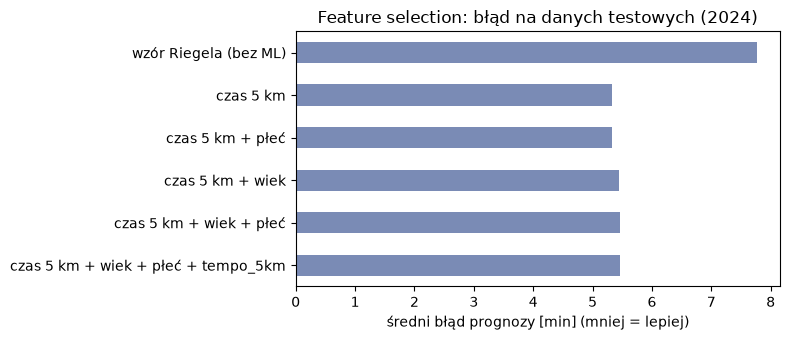

In [8]:
ax = porownanie["MAE [min]"].iloc[::-1].plot.barh(figsize=(8, 3.5), color="#7A8BB5")
ax.set_xlabel("średni błąd prognozy [min] (mniej = lepiej)")
ax.set_title("Feature selection: błąd na danych testowych (2024)")
plt.tight_layout()
plt.show()

### 4.4 Czy to nie przypadek jednego roku?

Powtarzamy porównanie w drugą stronę (trening 2024, test 2023) i dodatkowo walidacją krzyżową (5-fold) na obu latach razem.

In [9]:
from sklearn.model_selection import KFold, cross_val_score

stabilnosc = {}
for nazwa, cechy in zestawy.items():
    r = {}
    for a, b in [(2023, 2024), (2024, 2023)]:
        A, B = df[df["rok"] == a], df[df["rok"] == b]
        r[f"MAE: trening {a}, test {b}"] = mean_absolute_error(B["meta"], hgb(cechy).fit(A[cechy], A["meta"]).predict(B[cechy])) / 60
    r["MAE: 5-fold CV"] = -cross_val_score(hgb(cechy), df[cechy], df["meta"], scoring="neg_mean_absolute_error",
                                           cv=KFold(5, shuffle=True, random_state=0)).mean() / 60
    stabilnosc[nazwa] = r
pd.DataFrame(stabilnosc).T.round(3)

,"MAE: trening 2023, test 2024","MAE: trening 2024, test 2023",MAE: 5-fold CV
czas 5 km,5.326,5.158,4.914
czas 5 km + płeć,5.326,5.161,4.915
czas 5 km + wiek,5.451,5.181,4.913
czas 5 km + wiek + płeć,5.456,5.169,4.916
czas 5 km + wiek + płeć + tempo_5km,5.456,5.169,4.916


### 4.5 Ważność cech (permutation importance)

Mieszamy losowo jedną cechę w danych testowych i patrzymy, o ile rośnie błąd. Im większy wzrost, tym ważniejsza cecha.

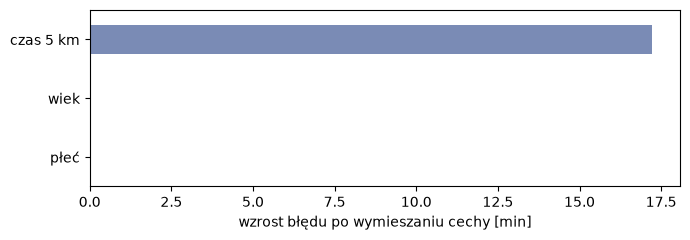

,wzrost MAE [min]
płeć,0.017
wiek,0.031
czas 5 km,17.216


In [10]:
CECHY = ["t5", "wiek", "kobieta"]
m = hgb(CECHY).fit(tr[CECHY], tr["meta"])
pi = permutation_importance(m, te[CECHY], te["meta"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
waznosc = pd.Series(pi.importances_mean / 60, index=["czas 5 km", "wiek", "płeć"]).sort_values()
ax = waznosc.plot.barh(figsize=(7, 2.5), color="#7A8BB5")
ax.set_xlabel("wzrost błędu po wymieszaniu cechy [min]")
plt.tight_layout()
plt.show()
waznosc.round(3).to_frame("wzrost MAE [min]")

### 4.6 Wniosek

- **Czas na 5 km** niesie prawie całą informację: sam daje błąd ok. 5 min i jest wyraźnie lepszy od wzoru Riegela (ok. 7,8 min).
- **Wiek i płeć** po podaniu czasu na 5 km praktycznie nic nie dodają — różnice w błędzie to 0–8 sekund
  (permutation importance: kilka sekund). Ich wpływ jest już „ukryty” w czasie na 5 km.
  Nie pogarszają jednak modelu w walidacji krzyżowej, więc **zostawiamy je**: są wymagane w zadaniu jako dane wejściowe,
  aplikacja i tak ich używa (porównanie z grupą płeć + wiek), a model może wykorzystać je u osób nietypowych.
- **tempo_5km** to tylko przeskalowany czas na 5 km — nic nie wnosi, **odrzucamy**.
- Kolumny z wyciekiem (międzyczasy 10–20 km, miejsca, tempo) — **odrzucone**, bo nie są znane przed biegiem.

**Wybrane cechy: czas na 5 km, wiek, płeć** — te same wyciąga z tekstu użytkownika LLM w aplikacji.

## 5. Trening modelu do aplikacji

Dla wybranych cech trenujemy:
- **3 modele czasu na mecie** z regresją kwantylową: szybki wariant (5. percentyl), najbardziej prawdopodobny (mediana) i wolny wariant (95. percentyl) — z nich aplikacja pokazuje prognozę i zakres,
- **modele międzyczasów** na 10/15/20 km — do planu tempa.

Aplikacja przyjmuje też czas na 10 km, więc ten sam zestaw powstaje dla wejścia 10 km.

In [11]:
KWANTYLE = {"dol": 0.05, "p50": 0.5, "gora": 0.95}


def X_z(d, wej_km):
    return d[["wiek", "kobieta"]].assign(czas_wej=d[f"t{wej_km}"])


def zbuduj(d, wej_km):
    X = X_z(d, wej_km)
    modele = {"meta": {}, "splity": {}}
    for nazwa, q in KWANTYLE.items():
        modele["meta"][nazwa] = hgb(list(X.columns), "quantile", q).fit(X, d["meta"])
    for km in SPLITY:
        if km > wej_km:
            modele["splity"][km] = hgb(list(X.columns)).fit(X, d[f"t{km}"])
    return modele


def ocen(d_tr, d_te, wej_km):
    mod = zbuduj(d_tr, wej_km)
    X, y = X_z(d_te, wej_km), d_te["meta"].to_numpy()
    dol, p50, gora = (mod["meta"][k].predict(X) for k in ("dol", "p50", "gora"))
    riegel = d_te[f"t{wej_km}"].to_numpy() * (DYSTANS / wej_km) ** 1.06
    return {
        "mae_min": round(mean_absolute_error(y, p50) / 60, 2),
        "mae_riegel_min": round(mean_absolute_error(y, riegel) / 60, 2),
        "r2": round(r2_score(y, p50), 3),
        "pokrycie_przedzialu": round(float(np.mean((y >= dol) & (y <= gora))), 3),
        "n_test": int(len(y)),
    }


met = {f"{km}km": ocen(tr, te, km) for km in (5, 10)}
met["n_trening_finalny"] = int(len(df))
pd.DataFrame({k: v for k, v in met.items() if isinstance(v, dict)}).T

,mae_min,mae_riegel_min,r2,pokrycie_przedzialu,n_test
5km,5.45,7.77,0.867,0.805,9975.0
10km,3.69,3.59,0.935,0.844,9975.0


`pokrycie_przedzialu` mówi, jaka część prawdziwych wyników z 2024 trafiła w zakres prognozy — tę liczbę pokazuje aplikacja („80% szans”).

Po ocenie trenujemy model **na obu latach** — to wersja, która trafia do aplikacji.

In [12]:
pakiet = {
    "wersja": datetime.now().strftime("%Y-%m-%d_%H%M"),
    "cechy": ["wiek", "kobieta", "czas_wej"],
    "modele": {km: zbuduj(df, km) for km in (5, 10)},
    # rozkład prawdziwych wyników — do pozycji w stawce (płeć + dekada wieku)
    "rozklad": {
        "kobieta": df["kobieta"].to_numpy(dtype="int8"),
        "dekada": (df["wiek"] // 10 * 10).clip(20, 70).to_numpy(dtype="int16"),
        "meta": df["meta"].to_numpy(dtype="int32"),
    },
    "metryki": met,
}
print("Nowa wersja modelu:", pakiet["wersja"])

Nowa wersja modelu: 2026-11-25_1309


## 6. Zapis nowej wersji — lokalnie i do Digital Ocean Spaces

In [13]:
(MODEL_DIR / "wersje").mkdir(parents=True, exist_ok=True)
plik_wersji = MODEL_DIR / "wersje" / f"tempomat_{pakiet['wersja']}.joblib"
joblib.dump(pakiet, plik_wersji, compress=3)
joblib.dump(pakiet, MODEL_DIR / "tempomat.joblib", compress=3)  # tego pliku używa aplikacja
(MODEL_DIR / "metryki.json").write_text(json.dumps(met, indent=2, ensure_ascii=False), encoding="utf-8")
print("Zapisano lokalnie:", plik_wersji, "oraz", MODEL_DIR / "tempomat.joblib")

if SPACES:
    for lokalny, klucz in [(plik_wersji, MODEL_PREFIX + plik_wersji.name),
                           (MODEL_DIR / "tempomat.joblib", MODEL_PREFIX + "tempomat.joblib"),
                           (MODEL_DIR / "metryki.json", MODEL_PREFIX + "metryki.json")]:
        s3.upload_file(Filename=str(lokalny), Bucket=BUCKET_NAME, Key=klucz)
        print("Wysłano do Spaces:", klucz)
else:
    print("Pomijam wysyłkę do Spaces — brak konfiguracji w .env.")

Zapisano lokalnie: model\wersje\tempomat_2026-11-25_1309.joblib oraz model\tempomat.joblib


Wysłano do Spaces: runcast/models/tempomat_2026-11-25_1309.joblib


Wysłano do Spaces: runcast/models/tempomat.joblib


Wysłano do Spaces: runcast/models/metryki.json
